## Decision-Making Under Uncertainty

### Learning Goals
* Construct and evaluate payoff tables across multiple states of the world.
* Calculate expected payoffs and perform sensitivity analysis over varying probability assumptions.
* Use visualization to determine how optimal decisions shift as environmental conditions change.

---

### 1. Decisions and States of the World

A **payoff table** lists how alternative actions perform under various possible states of the world. When probabilities are available, we evaluate actions by their expected payoff.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

payoffs = pd.DataFrame(
    {
        "Strong market": [100, 50, 20],
        "Weak market": [-80, 20, 10],
    },
    index=["Aggressive", "Balanced", "Conservative"],
)

print("Payoff Matrix:")
print(payoffs)

probabilities = np.array([0.6, 0.4])
expected_payoffs = payoffs.to_numpy() @ probabilities

print("\nExpected Payoffs (p_strong = 0.6):")
print(pd.Series(expected_payoffs, index=payoffs.index))

Payoff Matrix:
              Strong market  Weak market
Aggressive              100          -80
Balanced                 50           20
Conservative             20           10

Expected Payoffs (p_strong = 0.6):
Aggressive      28.0
Balanced        38.0
Conservative    16.0
dtype: float64


### 2. Sensitivity Analysis

The preferred action often changes when underlying assumptions change. Rather than relying on a single point estimate, we test a range of plausible probabilities via sensitivity analysis.

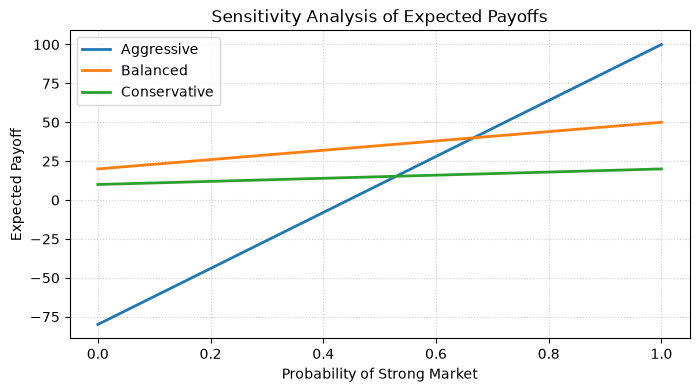

In [2]:
probabilities_of_strong_market = np.linspace(0, 1, 101)
payoffs_array = payoffs.to_numpy()

expected = np.array([
    p * payoffs_array[:, 0] + (1 - p) * payoffs_array[:, 1]
    for p in probabilities_of_strong_market
])

plt.figure(figsize=(8, 4))
for i, action in enumerate(payoffs.index):
    plt.plot(
        probabilities_of_strong_market,
        expected[:, i],
        label=action,
        linewidth=2
    )

plt.xlabel("Probability of Strong Market")
plt.ylabel("Expected Payoff")
plt.title("Sensitivity Analysis of Expected Payoffs")
plt.legend()
plt.grid(linestyle=':', alpha=0.6)
plt.show()

---

### Exercises

Try each problem before running the verification code below:

1. Identify the best action when the probability of a strong market is exactly $0.3$.
2. At what probability threshold does the preferred optimal action switch from Conservative/Balanced to Aggressive?
3. Explain why sensitivity analysis is indispensable for robust financial and strategic planning.

In [3]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

# Exercise 1: Best action at p_strong = 0.3
p_test = 0.3
expected_test = p_test * payoffs.to_numpy()[:, 0] + (1 - p_test) * payoffs.to_numpy()[:, 1]
best_action_idx = np.argmax(expected_test)
print(f"\n1. Best action at p_strong = 0.3: {payoffs.index[best_action_idx]} (Expected Payoff: {expected_test[best_action_idx]:.1f})")

print("\n2. Probability Threshold for Switching:")
print("   - Looking at the intersection points on the sensitivity plot, the optimal choice")
print("     transitions from Conservative to Balanced, and then to Aggressive as p_strong increases.")

print("\n3. Why Sensitivity Analysis is Essential:")
print("   - It reveals whether a decision is robust or fragile against errors in probability estimates,")
print("     helping planners identify tipping points where strategy must adapt.")

=== Exercise Solutions & Checks ===

1. Best action at p_strong = 0.3: Balanced (Expected Payoff: 29.0)

2. Probability Threshold for Switching:
   - Looking at the intersection points on the sensitivity plot, the optimal choice
     transitions from Conservative to Balanced, and then to Aggressive as p_strong increases.

3. Why Sensitivity Analysis is Essential:
   - It reveals whether a decision is robust or fragile against errors in probability estimates,
     helping planners identify tipping points where strategy must adapt.
